## Documentation 
This notebook tries to cross-compare kinbert and phosphoPCA prediction. For the directly kinbert prediction on the phosphoPCA true positive set, it is in the ksi_ml project directory


In [741]:
import pandas as pd
import numpy as np
import scipy
def assign_paabd(dat,train_dat = None,assign_kinase = False,get_sub_15 = True):
    if get_sub_15:
        dat["substrate_seq_15aa"] = dat.apply(lambda s: s["substrate_seq"][s["p_ind"]-1-7:s["p_ind"]-1+8],axis = 1)
    dat = dat.loc[dat["substrate_seq_15aa"].apply(lambda s:len(s))==15,:]
    dat.loc[:,"SH2"] = dat["substrate_seq_15aa"].apply(lambda s: s[7]=='Y')
    dat.loc[:,"b14-3-3"] = dat["substrate_seq_15aa"].apply(lambda s: ((s[7]=='S')|(s[7]=='T'))&(s[4]=='R')&(s[9]=='P'))
    dat.loc[:,"WW"] = dat["substrate_seq_15aa"].apply(lambda s: ((s[7]=='S')|(s[7]=='T'))&(s[8]=='P'))
    dat.loc[:,"FHA"] = dat["substrate_seq_15aa"].apply(lambda s: ((s[7]=='T'))&(s[10] in ["D"]))
    if assign_kinase:
        dat = pd.merge(dat,train_dat.loc[:,["kinase","kinase_seq"]].drop_duplicates(), on = "kinase_seq")
    return dat     

In [742]:
blib_kinases_with_acc = pd.read_csv('../screening_analysis/blib_kinases_with_acc.csv',header = None)
blib_kinases_with_acc.columns = ['kinase_type','kinase','kinase_seq','kinase_acc']
dat_in_screen = pd.read_pickle('./251203_ksi_reduced_df_tp.pkl')
dat_in_screen = pd.merge(blib_kinases_with_acc,dat_in_screen,left_on = 'kinase',right_on = 'kinase')
dat_in_screen.columns = ['kinase_type', 'kinase', 'kinase_seq', 'kinase_acc', 'substrate_seq_15aa',
       'positive', 'paabd_hit', 'paabd_all', 'n_paabd', 'hit_count',
       'binding_max', 'binding_best_hit', 'lfsr_min', 'lfsr_best_hit',
       'fp_sub', 'true_positive']
dat_in_screen = assign_paabd(dat_in_screen,get_sub_15 = False)


### Inspection of dblysate trained model performance on phosphoPCA dataset

In [743]:
tape_score = pd.read_csv('./exp_tape_bertbase_sep_v2_early_loss__ksi_full.csv').iloc[:,1:]
# tape_score = tape_score.loc[:,['kinase_domain_seq','substrate_seq_15aa','prob','logit']]

In [744]:
tape_score.columns = ['kinase_domain_seq','substrate_seq_15aa','tape_prob','tape_logit']

In [745]:
tape_score_aug = pd.read_csv('./pairs_aug_ksi_full.csv').iloc[:,1:]
# the label in this file was a placeholder and was default to true for all the phosphoPCA experiment data and to false to all db-sampled negative data

/tmp/ipykernel_139/2167175119.py:1: DtypeWarning: Columns (0: substrate) have mixed types. Specify dtype option on import or set low_memory=False.


In [746]:
tape_score = pd.merge(tape_score_aug,tape_score,on = ['kinase_domain_seq','substrate_seq_15aa'])

In [747]:
tape_score = tape_score.loc[:,['kinase_human_name','kinase_domain_seq','substrate_seq_15aa','tape_prob','tape_logit']]

In [748]:
tape_score.columns = ['kinase','kinase_domain_seq','substrate_seq_15aa','tape_prob','tape_logit']

In [749]:
tape_score.loc[tape_score['kinase']=='JAK2_HUMAN','kinase'] = 'JAK2_HUMAN_1'
tape_score.loc[tape_score['kinase']=='KS6B1_HUMAN','kinase'] = 'KS6B1_HUMAN_active'
tape_score.loc[tape_score['kinase']=='PLK1_HUMAN','kinase'] = 'PLK1_HUMAN_active'

In [750]:
dat_in_screen = pd.merge(dat_in_screen,tape_score, on = ['kinase','substrate_seq_15aa' ])

In [751]:
df = dat_in_screen.loc[:,['kinase_type', 'kinase', 'kinase_seq', 'kinase_acc',
       'substrate_seq_15aa', 'positive', 'binding_max', 'binding_best_hit', 'lfsr_min',
       'lfsr_best_hit', 'fp_sub', 'true_positive', 'SH2', 'b14-3-3', 'WW',
       'FHA', 'tape_prob', 'tape_logit']]

In [752]:
df = df.loc[~df['kinase'].isin(['KS6B1_HUMAN_active','PLK1_HUMAN_active']),:]

In [753]:
import pandas as pd
import numpy as np
from sklearn.metrics import *
import matplotlib.pyplot as plt
import seaborn as sns
from plotnine import *

In [754]:
df['wpaabd'] = (df['SH2'])|(df['b14-3-3'])|(df['WW'])|(df['FHA'])

In [755]:
df.groupby('true_positive').count().reset_index().iloc[:,[0,1]]

,true_positive,kinase_type
0,False,22530
1,True,5603


In [756]:
plot_df = df.copy()

In [757]:
# 1: plot_df['true_positive'] = True
# 2: (plot_df['true_positive'] = False) &(plot_df['fp_sub'] = True)
# 3: (plot_df['true_positive'] = False) &(plot_df['fp_sub'] = False)
# 4: (plot_df['true_positive'] = False) &(plot_df['wpaabd'] = True)
# 5: (plot_df['true_positive'] = False) &(plot_df['wpaabd'] = False)
# 6: (plot_df['true_positive'] = False) &(plot_df['binding_max']>1)

In [758]:
import numpy as np
import pandas as pd
from plotnine import *

# -----------------------------
# 1) Overlapping labels
# -----------------------------

def get_labels(row):
    labels = []
    # labels.append("0: Background")
    if bool(row["true_positive"]):
        labels.append("True Positive")

    if not bool(row["true_positive"]):
        labels.append("Not True Positive")
        
    # if (not bool(row["true_positive"])) and bool(row["fp_sub"]):
    #     labels.append("2: FP_sub")

    # if (not bool(row["true_positive"])) and (not bool(row["fp_sub"])):
    #     labels.append("3: TN + No FP_sub")

    # if (not bool(row["true_positive"])) and bool(row["wpaabd"]):
    #     labels.append("4: WPAABD True")

    # if (not bool(row["true_positive"])) and (not bool(row["wpaabd"])):
    #     labels.append("5: WPAABD False")

    # if (not bool(row["true_positive"])) and (float(row["binding_max"]) > 1):
    #     labels.append("6: binding_max > 1")

    # if (not bool(row["true_positive"])) and (float(row["binding_max"]) > 0.5):
    #     labels.append("7: binding_max > 0.5")

    # if len(labels) == 0:
    #     labels = ["Uncategorized"]

    return labels


# Explode rows so each row can have multiple labels
plot_df['labels'] = plot_df.apply(get_labels, axis=1)
plot_exploded = plot_df.explode('labels')

p = (ggplot(plot_exploded, aes(x='tape_logit', fill='labels', color='labels')) +
     geom_density(alpha=0.3) +
     labs(
         title='TAPE Score Distribution by Category',
         x='TAPE Probability',
         y='Density',
         fill='Category',
         color='Category'
     ) +
     theme_minimal() +
     theme(
         figure_size=(12, 6),
         plot_title=element_text(size=14, face='bold')
     )
)

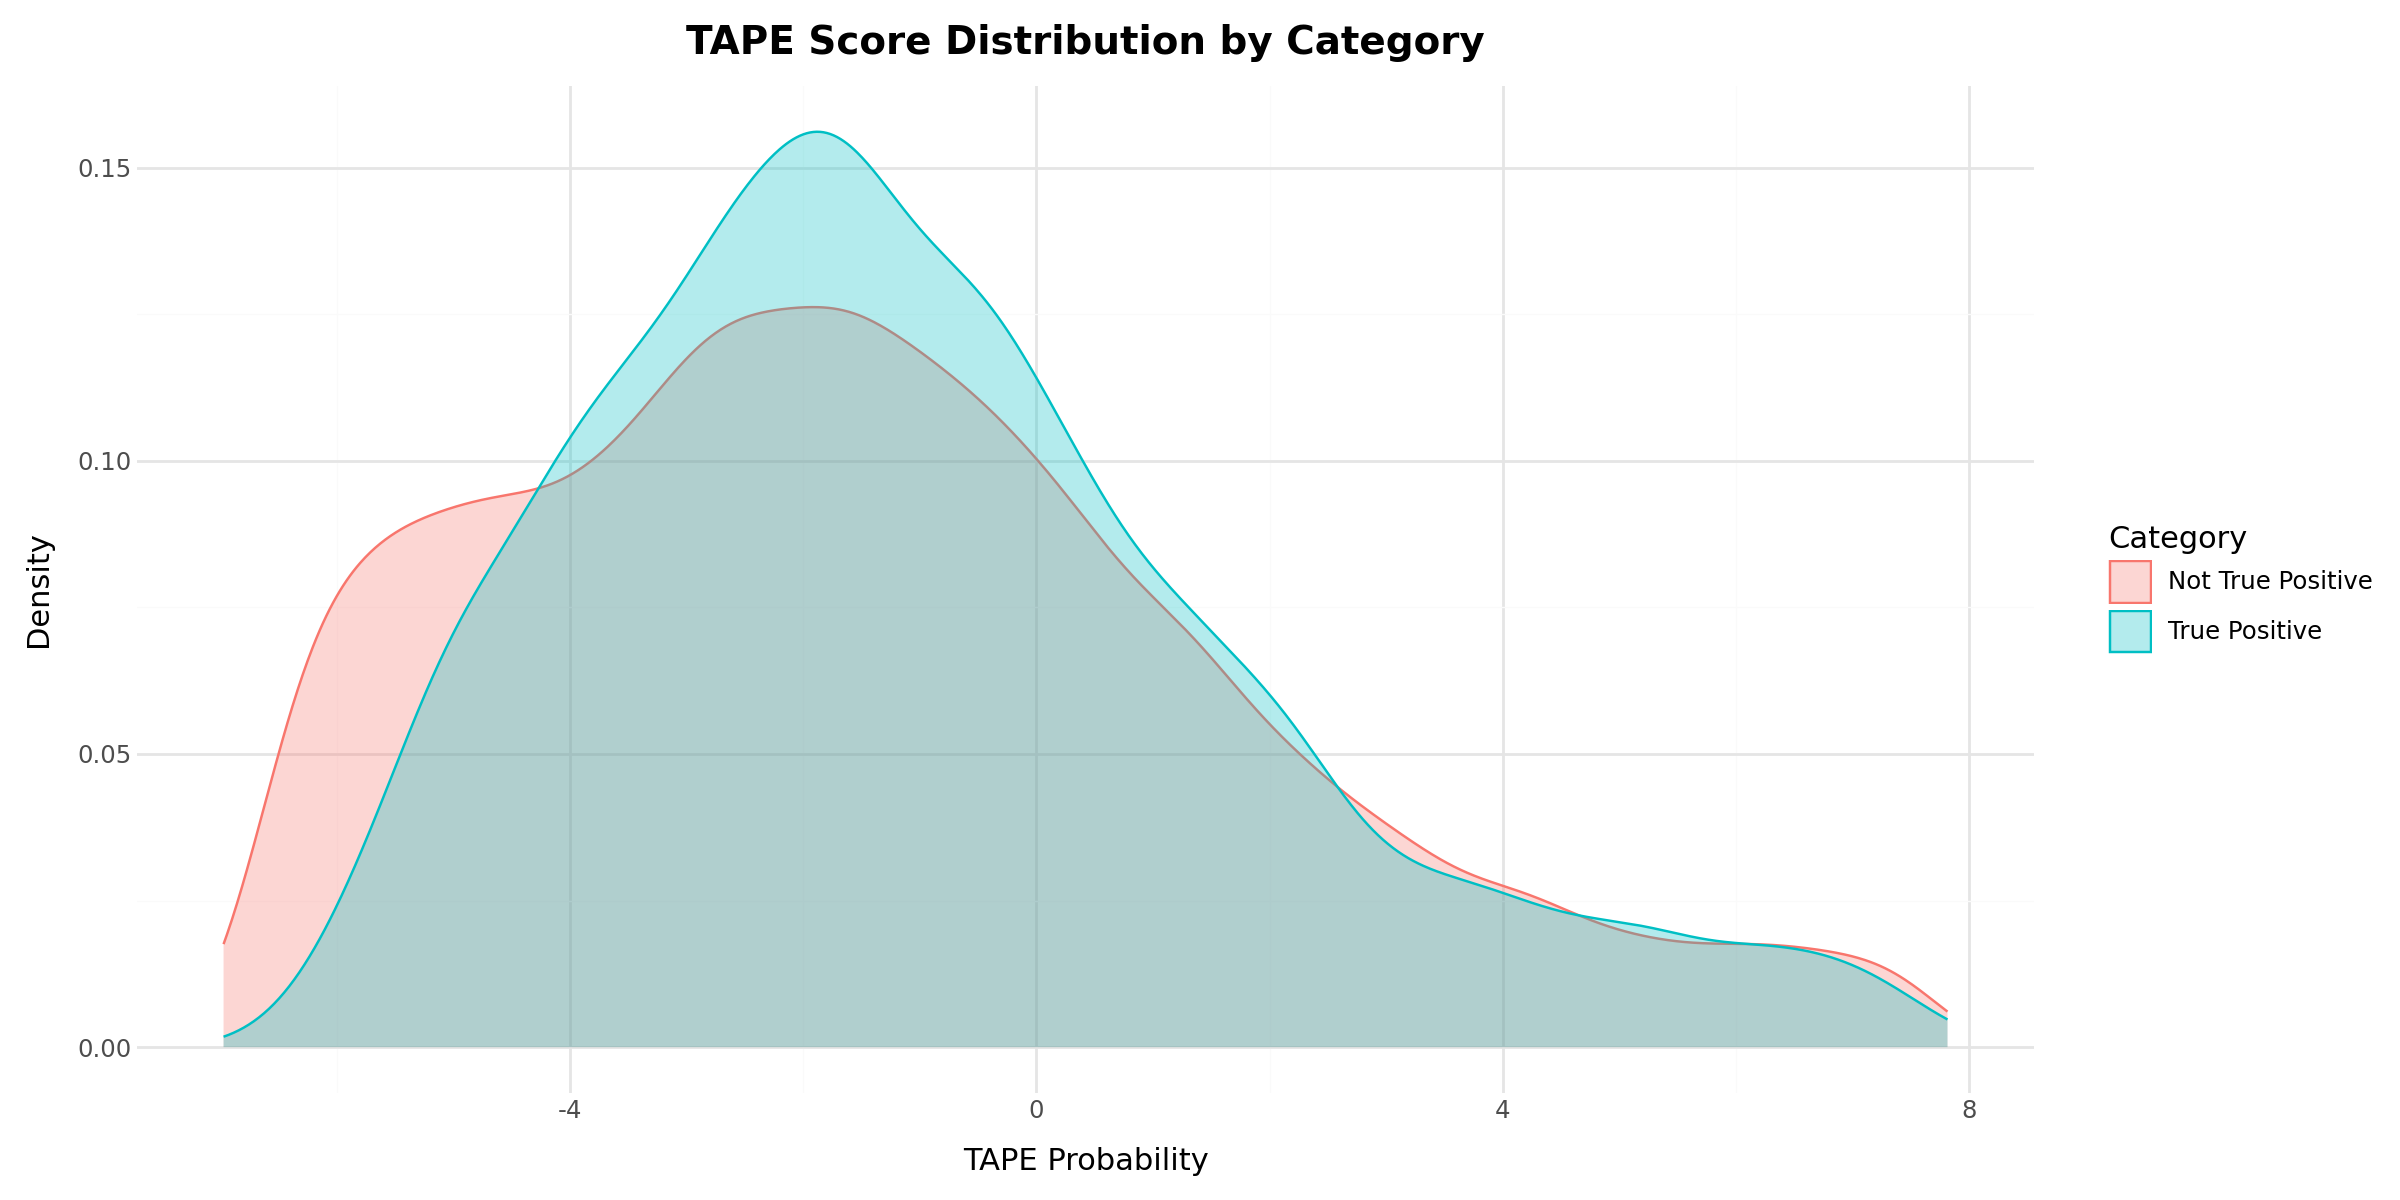

In [759]:
p

### Output phosphoPCA finetuning dataset for further tuning of the kinbert data

Negative: not fp_sub + binding_max<-0.1
Positive: True positive sets
For the ones overlap with databased but missing, remove them to avoid contradiction

Yeast Positive: positive yeast-MS
Yeast Positive: resample new yeast-MS

In [760]:
negative_set = df.loc[(df['fp_sub']==False)&(df['true_positive']==False)&(df['binding_max']<-0.1),:]
negative_set['label']=0

In [761]:
negative_set.shape

(6463, 20)

In [762]:
positive_set = df.loc[(df['true_positive']==True),:]
positive_set['label']=1

In [763]:
positive_set.shape

(5603, 20)

In [764]:
finetune_dataset = pd.concat([positive_set,negative_set])

In [765]:
finetune_dataset = finetune_dataset.loc[:,['kinase','substrate_seq_15aa','binding_max','fp_sub','true_positive','label']]

In [766]:
finetune_dataset.to_csv('./260210_exp_ksi_fintuning_data.csv')

### Compare the performance of the phosphoPCA data tuned VS dblysate trained data performance

In [767]:
tape_score_fintuned = pd.read_csv('./finetune_tape_v2_phosphopca_exp6__pairs_aug_ksi_full.csv').iloc[:,1:]
tape_score_fintuned = tape_score_fintuned.loc[:,['kinase_domain_seq','substrate_seq_15aa','prob','logit']]
tape_score_fintuned.columns = ['kinase_domain_seq','substrate_seq_15aa','tape_prob','tape_logit']

/tmp/ipykernel_139/2696555187.py:1: DtypeWarning: Columns (0: substrate) have mixed types. Specify dtype option on import or set low_memory=False.


In [768]:
tape_score_fintuned_aug = pd.read_csv('./pairs_aug_ksi_full.csv').iloc[:,1:]
tape_score_fintuned = pd.merge(tape_score_fintuned_aug,tape_score_fintuned,on = ['kinase_domain_seq','substrate_seq_15aa'])


/tmp/ipykernel_139/1859464045.py:1: DtypeWarning: Columns (0: substrate) have mixed types. Specify dtype option on import or set low_memory=False.


In [769]:
tape_score_fintuned = tape_score_fintuned.loc[:,['kinase_human_name','substrate_seq_15aa','tape_prob','tape_logit']]
tape_score_fintuned.columns = ['kinase','substrate_seq_15aa','tape_prob','tape_logit']
tape_score_fintuned.loc[tape_score_fintuned['kinase']=='JAK2_HUMAN','kinase'] = 'JAK2_HUMAN_1'
tape_score_fintuned.loc[tape_score_fintuned['kinase']=='KS6B1_HUMAN','kinase'] = 'KS6B1_HUMAN_active'
tape_score_fintuned.loc[tape_score_fintuned['kinase']=='PLK1_HUMAN','kinase'] = 'PLK1_HUMAN_active'

In [770]:
tape_score_fintuned = tape_score_fintuned.drop_duplicates()
tape_score_fintuned.columns = ['kinase','substrate_seq_15aa','tape_prob_finetuned','tape_logit_finetuned']

In [771]:
df_finetuned = pd.merge(df,tape_score_fintuned, on = ['kinase','substrate_seq_15aa'])

In [772]:
plot_df = df_finetuned.copy()

In [773]:
plot_df['labels'] = plot_df.apply(get_labels, axis=1)

In [774]:
plot_exploded = plot_df.explode('labels')

In [775]:
plot_long = plot_exploded.melt(
    id_vars=['labels'],                    # keep your category column
    value_vars=['tape_logit', 'tape_logit_finetuned'],
    var_name='model',
    value_name='score'
)

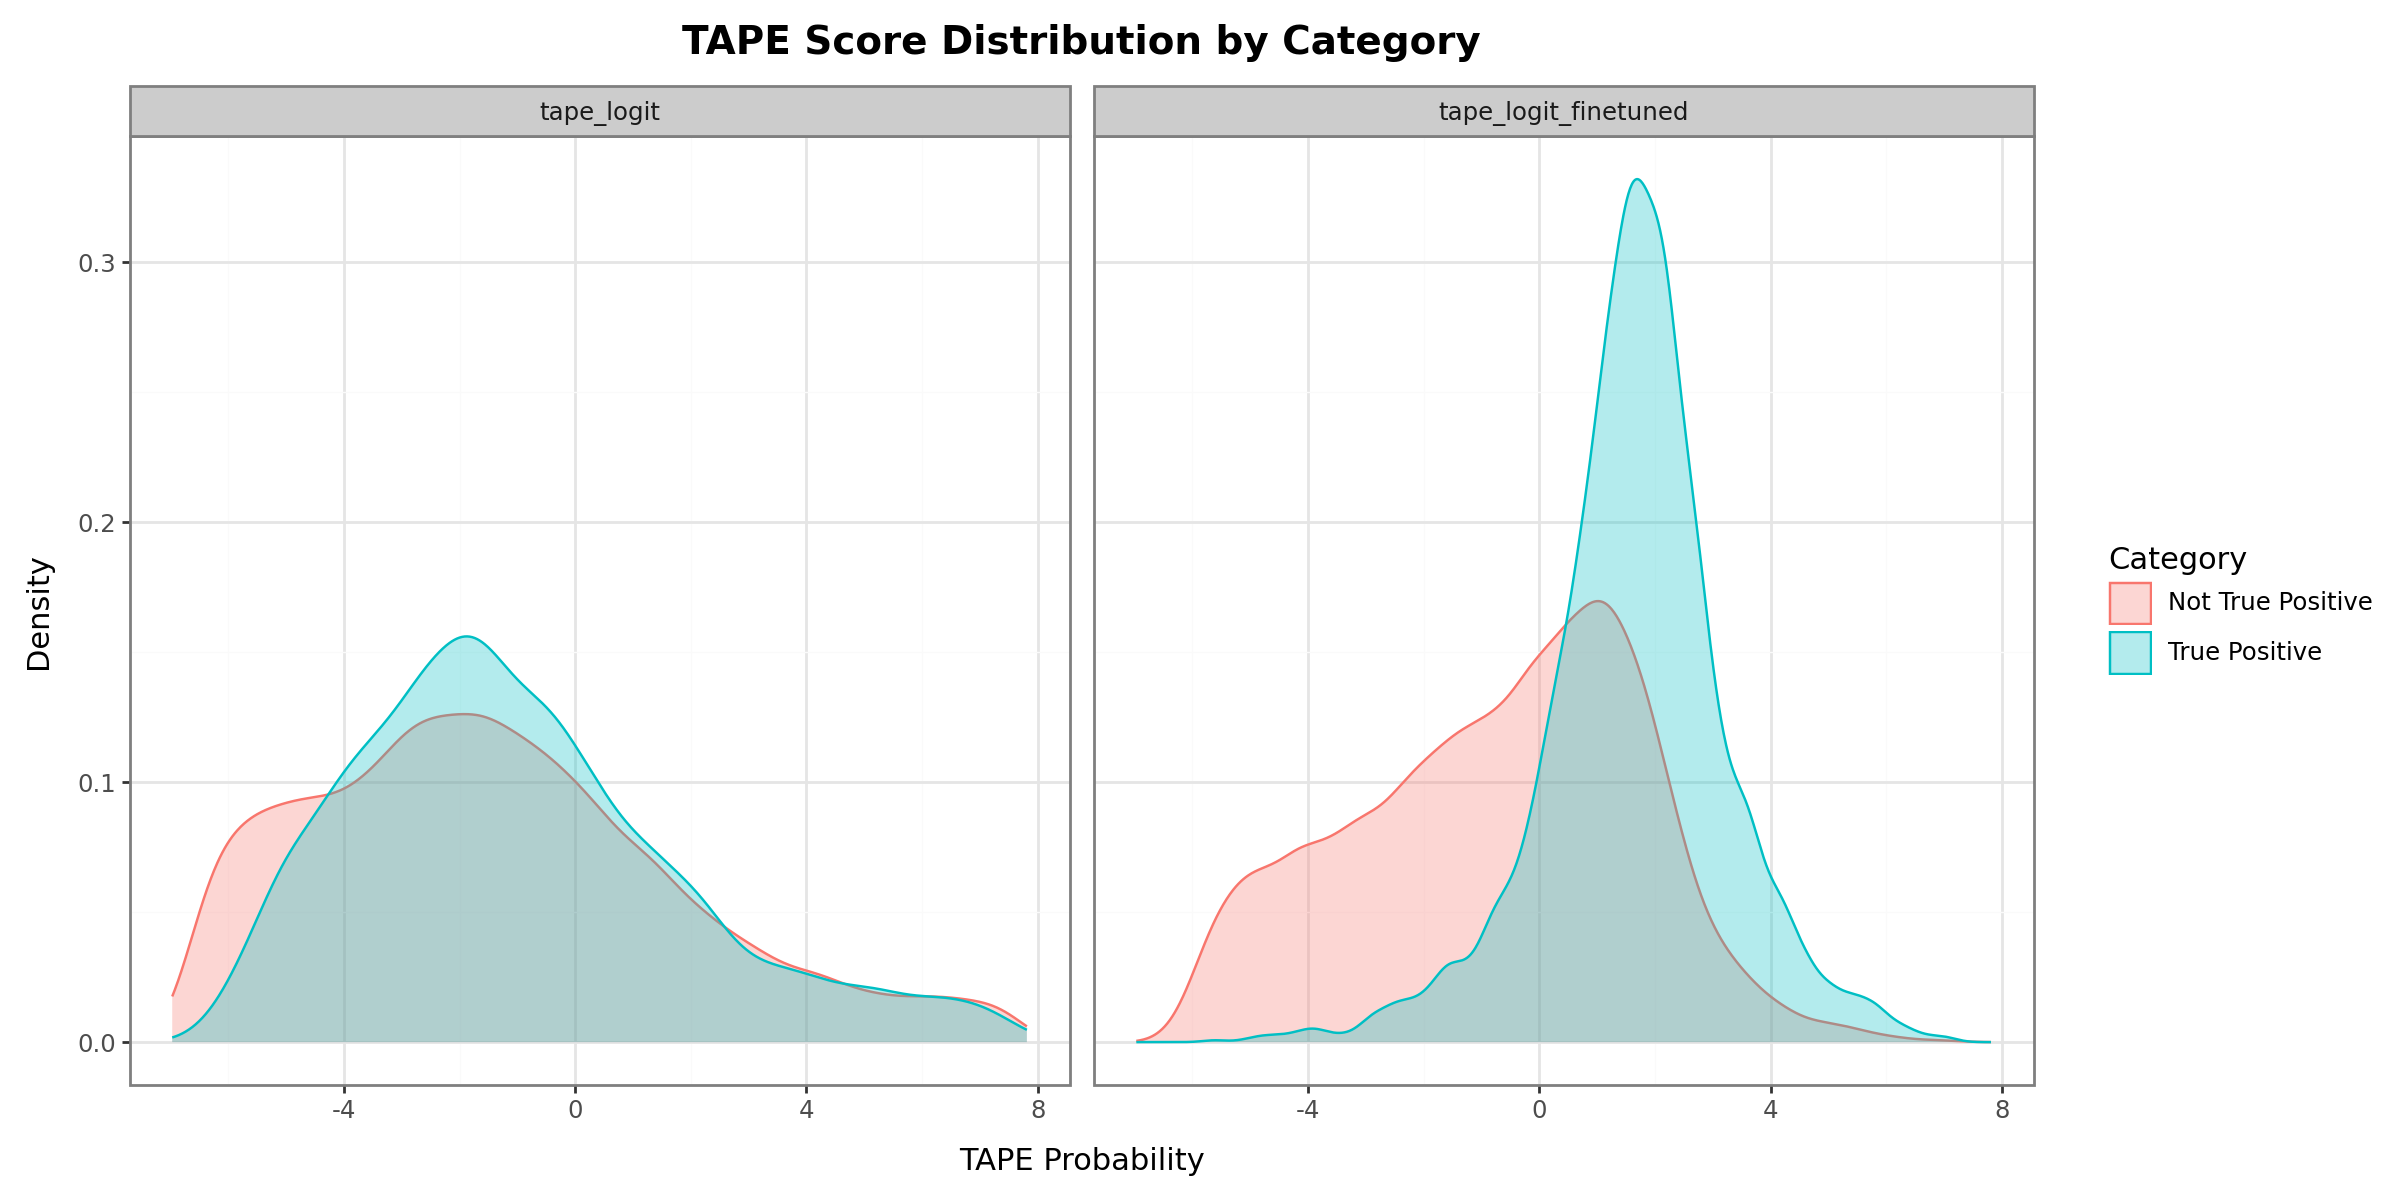

In [776]:
p = (
    ggplot(plot_long, aes(x='score', fill='labels', color='labels'))
    + geom_density(alpha=0.3)
    + facet_wrap('~model', nrow=1)
    + labs(
        title='TAPE Score Distribution by Category',
        x='TAPE Probability',
        y='Density',
        fill='Category',
        color='Category'
    )
    + theme_bw()
    + theme(
        figure_size=(12, 6),
        plot_title=element_text(size=14, weight='bold')
    )
)

p

In [777]:
p.save('finetuned_kinbert_distribution.pdf')

/opt/conda/lib/python3.11/site-packages/plotnine/ggplot.py:623: PlotnineWarning: Saving 12 x 6 in image.
/opt/conda/lib/python3.11/site-packages/plotnine/ggplot.py:624: PlotnineWarning: Filename: finetuned_kinbert_distribution.pdf


In [714]:
# rank 1 = highest logit within each kinase
df_finetuned["tape_logit_rank"] = (
    df_finetuned.groupby("kinase")["tape_logit"]
    .rank(method="dense", ascending=False)
    .astype(int)
)

df_finetuned["tape_logit_finetuned_rank"] = (
    df_finetuned.groupby("kinase")["tape_logit_finetuned"]
    .rank(method="dense", ascending=False)
    .astype(int)
)

In [719]:
df_finetuned.loc[(df_finetuned['kinase']=='TBK1_HUMAN')&(df_finetuned['substrate_seq_15aa']=='QGPSQTSTPTDVTAI')]

,kinase_type,kinase,kinase_seq,kinase_acc,substrate_seq_15aa,positive,binding_max,binding_best_hit,lfsr_min,lfsr_best_hit,...,b14-3-3,WW,FHA,tape_prob,tape_logit,wpaabd,tape_prob_finetuned,tape_logit_finetuned,tape_logit_rank,tape_logit_finetuned_rank
4247,ST,TBK1_HUMAN,WLLSDILGQGATANVFRGRHKKTGDLFAIKVFNNISFLRPVDVQMR...,Q9UHD2,QGPSQTSTPTDVTAI,True,1.241288,1.241288,0.0,0.0,...,False,True,True,0.200558,-1.320312,True,0.766206,1.426901,388,329


In [718]:
df_finetuned.loc[(df_finetuned['kinase']=='TBK1_HUMAN')&(df_finetuned['substrate_seq_15aa']=='SYRRGARSPEDGPSA')]

,kinase_type,kinase,kinase_seq,kinase_acc,substrate_seq_15aa,positive,binding_max,binding_best_hit,lfsr_min,lfsr_best_hit,...,b14-3-3,WW,FHA,tape_prob,tape_logit,wpaabd,tape_prob_finetuned,tape_logit_finetuned,tape_logit_rank,tape_logit_finetuned_rank
4397,ST,TBK1_HUMAN,WLLSDILGQGATANVFRGRHKKTGDLFAIKVFNNISFLRPVDVQMR...,Q9UHD2,SYRRGARSPEDGPSA,True,1.749151,1.749151,0.0,0.0,...,False,True,False,0.142888,-1.679688,True,0.676592,0.99795,424,483


In [720]:
df_finetuned.loc[(df_finetuned['kinase']=='IKKB_HUMAN')&(df_finetuned['substrate_seq_15aa']=='PHEEPSNSLMAIECR')]

,kinase_type,kinase,kinase_seq,kinase_acc,substrate_seq_15aa,positive,binding_max,binding_best_hit,lfsr_min,lfsr_best_hit,...,b14-3-3,WW,FHA,tape_prob,tape_logit,wpaabd,tape_prob_finetuned,tape_logit_finetuned,tape_logit_rank,tape_logit_finetuned_rank
14263,ST,IKKB_HUMAN,WEMKERLGTGGFGNVIRWHNQETGEQIAIKQCRQELSPRNRERWCL...,O14920,PHEEPSNSLMAIECR,True,1.623423,1.623423,0.0,0.0,...,False,False,False,0.952217,3.0,False,0.769495,1.420063,66,248


In [721]:
df_finetuned.loc[(df_finetuned['kinase']=='IKKB_HUMAN')&(df_finetuned['substrate_seq_15aa']=='LKICDFGTACDIQTH')]

,kinase_type,kinase,kinase_seq,kinase_acc,substrate_seq_15aa,positive,binding_max,binding_best_hit,lfsr_min,lfsr_best_hit,...,b14-3-3,WW,FHA,tape_prob,tape_logit,wpaabd,tape_prob_finetuned,tape_logit_finetuned,tape_logit_rank,tape_logit_finetuned_rank
14844,ST,IKKB_HUMAN,WEMKERLGTGGFGNVIRWHNQETGEQIAIKQCRQELSPRNRERWCL...,O14920,LKICDFGTACDIQTH,False,-0.212911,NaN,0.0735,NaN,...,False,False,True,0.83764,1.640625,True,0.380026,-0.208814,111,690


In [723]:
df_finetuned.to_pickle('./260212_ksi_reduced_df_tp_wtape.pkl')

In [727]:
finetune_tape_v2_phosphopca_exp6__pairs_aug_v2_train = pd.read_csv('finetune_tape_v2_phosphopca_exp6__pairs_aug_v2_train.csv')
finetune_tape_v2_phosphopca_exp6__pairs_aug_v2_test = pd.read_csv('finetune_tape_v2_phosphopca_exp6__pairs_aug_v2_test.csv')
finetune_tape_v2_phosphopca_exp6__pairs_aug_v2_val = pd.read_csv('finetune_tape_v2_phosphopca_exp6__pairs_aug_v2_val.csv')

In [728]:
finetune_tape_v2_phosphopca_exp6__pairs_aug_v2 = pd.concat([finetune_tape_v2_phosphopca_exp6__pairs_aug_v2_train,
          finetune_tape_v2_phosphopca_exp6__pairs_aug_v2_test,
          finetune_tape_v2_phosphopca_exp6__pairs_aug_v2_val])

In [736]:
%matplotlib inline

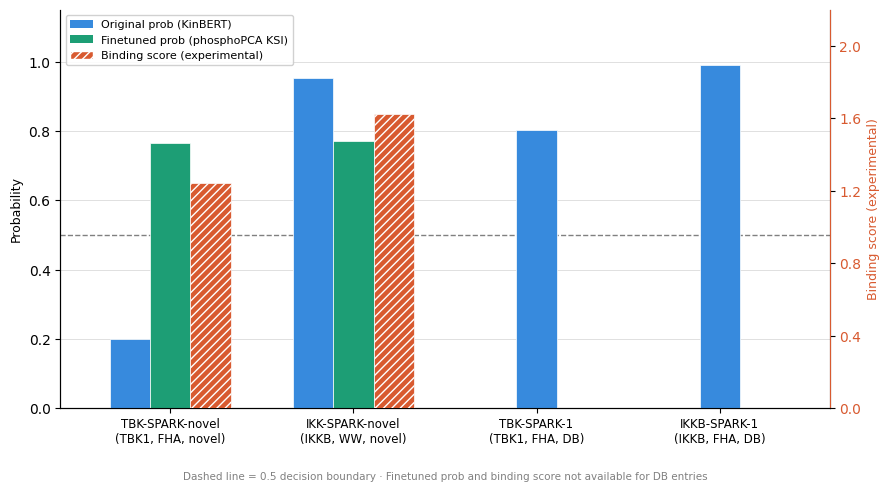

In [740]:
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

candidates = [
    "TBK-SPARK-novel\n(TBK1, FHA, novel)",
    "IKK-SPARK-novel\n(IKKB, WW, novel)",
    "TBK-SPARK-1\n(TBK1, FHA, DB)",
    "IKKB-SPARK-1\n(IKKB, FHA, DB)",
]

orig_prob     = [0.2006, 0.9522, 0.8032, 0.9902]
finetuned_prob = [0.7662, 0.7695, None,   None  ]
binding_score  = [1.2413, 1.6234, None,   None  ]

n = len(candidates)
x = np.arange(n)

# bar width and offsets — consistent width for all bars
bar_w = 0.22

# For candidates 0,1: three bars at offsets -bar_w, 0, +bar_w
# For candidates 2,3: one bar centered at 0 (no offset)
offsets_orig      = [-bar_w, -bar_w, 0,  0 ]
offsets_finetuned = [  0,      0,   None, None]
offsets_binding   = [ bar_w,  bar_w, None, None]

fig, ax1 = plt.subplots(figsize=(9, 5))
ax2 = ax1.twinx()

color_orig     = "#378ADD"
color_finetuned = "#1D9E75"
color_binding  = "#D85A30"

# --- plot original prob bars ---
for i in range(n):
    ax1.bar(x[i] + offsets_orig[i], orig_prob[i],
            width=bar_w, color=color_orig,
            edgecolor="white", linewidth=0.5, zorder=3)

# --- plot finetuned prob bars ---
for i in range(n):
    if finetuned_prob[i] is not None:
        ax1.bar(x[i] + offsets_finetuned[i], finetuned_prob[i],
                width=bar_w, color=color_finetuned,
                edgecolor="white", linewidth=0.5, zorder=3)

# --- plot binding score bars on ax2 with hatch ---
for i in range(n):
    if binding_score[i] is not None:
        ax2.bar(x[i] + offsets_binding[i], binding_score[i],
                width=bar_w, color=color_binding,
                hatch="////", edgecolor="white", linewidth=0.5,
                zorder=3)

# --- decision boundary on ax1 ---
ax1.axhline(0.5, color="gray", linestyle="--", linewidth=1, zorder=2)

# --- axes formatting ---
ax1.set_xticks(x)
ax1.set_xticklabels(candidates, fontsize=8.5)
ax1.set_ylabel("Probability", fontsize=9)
ax1.set_ylim(0, 1.15)
ax1.set_yticks(np.arange(0, 1.1, 0.2))
ax1.yaxis.label.set_color("black")
ax1.tick_params(axis="y", labelcolor="black")

ax2.set_ylabel("Binding score (experimental)", fontsize=9, color=color_binding)
ax2.set_ylim(0, 2.2)
ax2.set_yticks(np.arange(0, 2.1, 0.4))
ax2.tick_params(axis="y", labelcolor=color_binding)
ax2.spines["right"].set_edgecolor(color_binding)

ax1.set_xlim(-0.6, n - 0.4)
ax1.spines["top"].set_visible(False)
ax2.spines["top"].set_visible(False)
ax1.grid(axis="y", color="lightgray", linewidth=0.5, zorder=0)
ax1.set_axisbelow(True)

# --- legend ---
legend_handles = [
    mpatches.Patch(facecolor=color_orig,      label="Original prob (KinBERT)"),
    mpatches.Patch(facecolor=color_finetuned, label="Finetuned prob (phosphoPCA KSI)"),
    mpatches.Patch(facecolor=color_binding, hatch="////", edgecolor="white",
                   label="Binding score (experimental)"),
]
ax1.legend(handles=legend_handles, fontsize=8, frameon=True,
           loc="upper left", framealpha=0.9)

ax1.text(
    0.5, -0.18,
    "Dashed line = 0.5 decision boundary · Finetuned prob and binding score not available for DB entries",
    transform=ax1.transAxes, ha="center", fontsize=7.5, color="gray"
)

plt.tight_layout()
plt.savefig("kinase_prob_plot.pdf", bbox_inches="tight")
plt.show()